# FloraVision

Flower-species classification from photographs, packaged as a small MLOps pipeline.

The images are not tabular. Each photograph is resized, then described by color and texture measurements, and those measurements are what the model sees. This notebook is the offline half of the project: acquire the data, show the preprocessing, compare models, and check the prediction function. The API in `api/app.py` loads the same saved model for the live UI, retraining, and the load test.

Species: daisy, dandelion, rose, sunflower, tulip. The photographs are the TensorFlow `flower_photos` collection (Flickr images, Creative Commons Attribution).


## 1. Setup

The working directory is the repository root. Training images live in `data/train/<species>` and held-out images in `data/test/<species>`.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.config import CLASSES, FEATURE_COLUMNS, PRETTY, TEST_DIR, TRAIN_DIR
from src.model import load_story, retrain_status, train_and_save
from src.prediction import load_artifact, predict_path
from src.preprocessing import acquire_dataset, build_matrix, extract_features

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
print("Root:", ROOT)
print("Features:", ", ".join(FEATURE_COLUMNS))


Root: E:\Summative MLOP
Features: mean_r, mean_g, mean_b, std_luma, brightness, saturation, hue_sin, hue_cos, edge_density, green_ratio, yellow_ratio, red_ratio, colorfulness, center_edge_ratio, cell_00_r, cell_00_g, cell_00_b, cell_01_r, cell_01_g, cell_01_b, cell_02_r, cell_02_g, cell_02_b, cell_03_r, cell_03_g, cell_03_b, cell_04_r, cell_04_g, cell_04_b, cell_05_r, cell_05_g, cell_05_b, cell_06_r, cell_06_g, cell_06_b, cell_07_r, cell_07_g, cell_07_b, cell_08_r, cell_08_g, cell_08_b, cell_09_r, cell_09_g, cell_09_b, cell_10_r, cell_10_g, cell_10_b, cell_11_r, cell_11_g, cell_11_b, cell_12_r, cell_12_g, cell_12_b, cell_13_r, cell_13_g, cell_13_b, cell_14_r, cell_14_g, cell_14_b, cell_15_r, cell_15_g, cell_15_b, hue_bin_0, hue_bin_1, hue_bin_2, hue_bin_3, hue_bin_4, hue_bin_5, hue_bin_6, hue_bin_7


## 2. Data acquisition

`acquire_dataset` downloads the flower archive once, extracts it under `data/raw` (kept out of git), and copies a deterministic sample into the train and test folders.

- 400 training photographs per species
- 40 test photographs per species
- Shuffle seed 42, so the split does not change between machines
- No photograph is in both folders
- Each stored file is a 128×128 RGB JPEG

The test folder is not used to choose the model. It is only scored after the choice is fixed.


In [2]:
counts = acquire_dataset()
summary = pd.DataFrame(counts).rename(columns={"train": "train_images", "test": "test_images"})
summary.index.name = "species"
display(summary)
print("Total photographs:", int(summary.to_numpy().sum()))


Train and test folders already contain the working sample.


,train_images,test_images
species,,
daisy,400,40
dandelion,400,40
roses,400,40
sunflowers,400,40
tulips,400,40


Total photographs: 2200


## 3. Preprocessing

A raw photograph is not a row of numbers. Preprocessing makes one comparable row per image. The same function (`extract_features`) is used for training, for the API, and for retraining, so a photo uploaded in the UI is measured the same way as a training photo.

Steps for every image:

1. Open the file and convert it to RGB. Transparency and grayscale are expanded to three channels.
2. Resize to 128×128 with Lanczos resampling. Training files are already stored at this size; uploads are resized on arrival.
3. Scale pixel values from 0–255 to 0–1.
4. Convert RGB to HSV.
   - **Brightness** is the mean of the value channel.
   - **Saturation** is the mean of the saturation channel.
   - **Hue** is a circular mean, and only over pixels with saturation above 0.25. Pale pixels have an unstable hue, so they are left out. The mean is stored as sine and cosine so that red, which sits at both 0° and 360°, is not averaged into a nonsense angle.
5. **Edge density** is the mean magnitude of the luma gradient. Luma is `0.2126 R + 0.7152 G + 0.0722 B`. A dandelion head, made of many thin florets, scores higher than a broad rose petal.
6. **Center-edge ratio** compares the gradient in the middle half of the frame with the whole frame. Flowers are usually centered.
7. **Yellow ratio** and **red ratio** are the share of pixels in those hue bands that are also saturated. They make the species colors explicit instead of hoping a linear model invents them.
8. **Colorfulness** follows Hasler and Süsstrunk: the spread of the red–green and yellow–blue opponent channels.
9. Channel means, luma standard deviation, and the green share of the average color fill out lighting and foliage.
10. A 4×4 grid of mean red, green, and blue, so the model can tell a yellow center from a yellow corner. Sunflowers and daisies are obvious examples.
11. An 8-bin histogram of hue on saturated pixels, which keeps the mix of colors instead of only the average angle.

The dashboard interprets three of these measurements — hue, brightness with saturation, and edge density — because those are the ones you can see in a chart and explain in a sentence. The saved model also receives the grid and the histogram. Hand-built features are slower to reach the accuracy of a convolutional net, and they stay fast when Locust sends a flood of uploads.


Train rows 2000  |  test rows 200  |  columns 70


,train_rows
label,
daisy,400
dandelion,400
roses,400
sunflowers,400
tulips,400


,mean_r,mean_g,mean_b,std_luma,brightness,saturation,hue_sin,hue_cos,edge_density,green_ratio,...,cell_15_b,hue_bin_0,hue_bin_1,hue_bin_2,hue_bin_3,hue_bin_4,hue_bin_5,hue_bin_6,hue_bin_7,label
0,0.919,0.922,0.908,0.205,0.924,0.057,0.636,0.365,0.027,0.336,...,0.964,0.089,0.718,0.088,0.005,0.006,0.040,0.038,0.015,daisy
1,0.588,0.536,0.411,0.288,0.596,0.358,0.532,0.675,0.086,0.349,...,0.385,0.683,0.241,0.002,0.004,0.055,0.012,0.001,0.003,daisy
2,0.444,0.346,0.169,0.191,0.444,0.709,0.609,0.785,0.028,0.360,...,0.104,0.946,0.050,0.000,0.000,0.000,0.000,0.001,0.002,daisy
3,0.488,0.483,0.436,0.264,0.498,0.191,0.879,0.442,0.040,0.343,...,0.334,0.082,0.913,0.002,0.000,0.002,0.001,0.000,0.000,daisy
4,0.589,0.538,0.474,0.228,0.589,0.215,0.506,0.842,0.036,0.336,...,0.212,0.870,0.130,0.000,0.000,0.000,0.000,0.000,0.000,daisy
5,0.375,0.392,0.286,0.207,0.412,0.399,0.861,0.162,0.116,0.372,...,0.370,0.080,0.641,0.203,0.022,0.020,0.021,0.005,0.008,daisy
6,0.441,0.530,0.610,0.170,0.631,0.365,-0.398,-0.739,0.034,0.335,...,0.515,0.036,0.051,0.018,0.006,0.887,0.002,0.000,0.000,daisy
7,0.286,0.324,0.300,0.225,0.359,0.435,0.311,-0.260,0.083,0.356,...,0.365,0.015,0.465,0.088,0.049,0.367,0.012,0.000,0.002,daisy


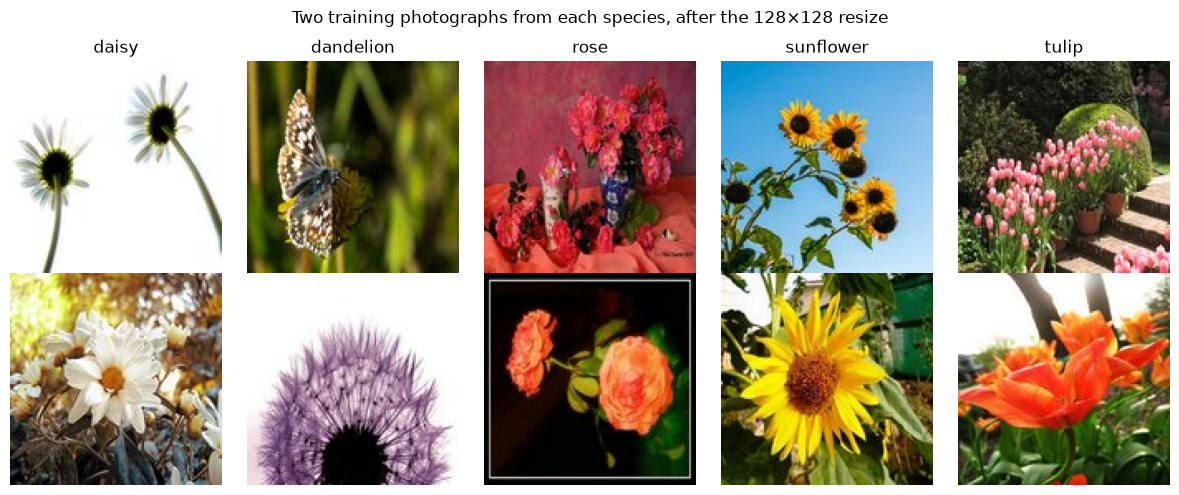

One feature vector for daisy
  mean_r               0.9192
  mean_g               0.9223
  mean_b               0.9075
  std_luma             0.2051
  brightness           0.9241
  saturation           0.0570
  hue_sin              0.6365
  hue_cos              0.3647
  edge_density         0.0273
  green_ratio          0.3355
  yellow_ratio         0.0074
  red_ratio            0.0000
  colorfulness         0.0495
  center_edge_ratio    1.0213
  cell_00_r            1.0000
  cell_00_g            1.0000
  cell_00_b            1.0000
  cell_01_r            1.0000
  cell_01_g            1.0000
  cell_01_b            1.0000
  cell_02_r            0.8940
  cell_02_g            0.9029
  cell_02_b            0.8895
  cell_03_r            0.9702
  cell_03_g            0.9691
  cell_03_b            0.9621
  cell_04_r            0.8136
  cell_04_g            0.8160
  cell_04_b            0.7795
  cell_05_r            0.9521
  cell_05_g            0.9536
  cell_05_b            0.9377
  cell_06_r

In [3]:
train_frame = build_matrix([TRAIN_DIR])
test_frame = build_matrix([TEST_DIR])
print(f"Train rows {len(train_frame)}  |  test rows {len(test_frame)}  |  columns {len(FEATURE_COLUMNS)}")
display(train_frame.groupby("label").size().rename("train_rows").to_frame())
display(train_frame[FEATURE_COLUMNS + ["label"]].head(8).round(3))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for column, label in enumerate(CLASSES):
    paths = sorted((TRAIN_DIR / label).glob("*.jpg"))[:2]
    for row, path in enumerate(paths):
        axes[row, column].imshow(plt.imread(path))
        axes[row, column].set_title(PRETTY[label] if row == 0 else "")
        axes[row, column].axis("off")
fig.suptitle("Two training photographs from each species, after the 128×128 resize")
fig.tight_layout()
plt.show()

sample = extract_features(train_frame.iloc[0]["path"])
print("One feature vector for", train_frame.iloc[0]["label"])
for key in FEATURE_COLUMNS:
    print(f"  {key:20s} {sample[key]:.4f}")


## 4. What three features say about the flowers

The charts below are the same files the UI serves. The sentences are computed from this sample, so they match the pictures rather than a fixed claim.

Read them as a story about the collection:

- Hue separates warm yellow blooms from red ones.
- Brightness and saturation separate pale, open flowers from darker leaves and petals.
- Edge density separates fine, repeated florets from smooth petals.

None of the three is a label on its own. Dandelions and sunflowers share yellow; texture and brightness help pull them apart. Roses and tulips share red; the same pair of extra measurements keeps them from collapsing together.


,brightness,saturation,edge_density,yellow_ratio,red_ratio
label,,,,,
daisy,0.475,0.427,0.058,0.063,0.009
dandelion,0.480,0.483,0.049,0.107,0.005
roses,0.522,0.480,0.057,0.041,0.145
sunflowers,0.561,0.601,0.069,0.224,0.017
tulips,0.536,0.526,0.066,0.073,0.121


**hue.png**

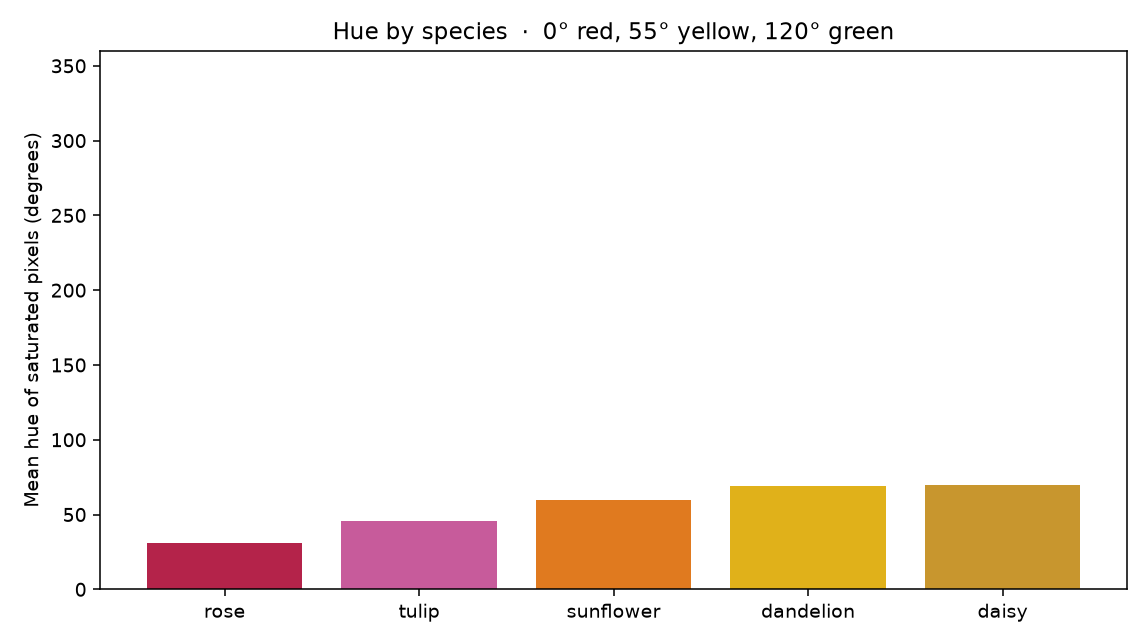

**brightness_saturation.png**

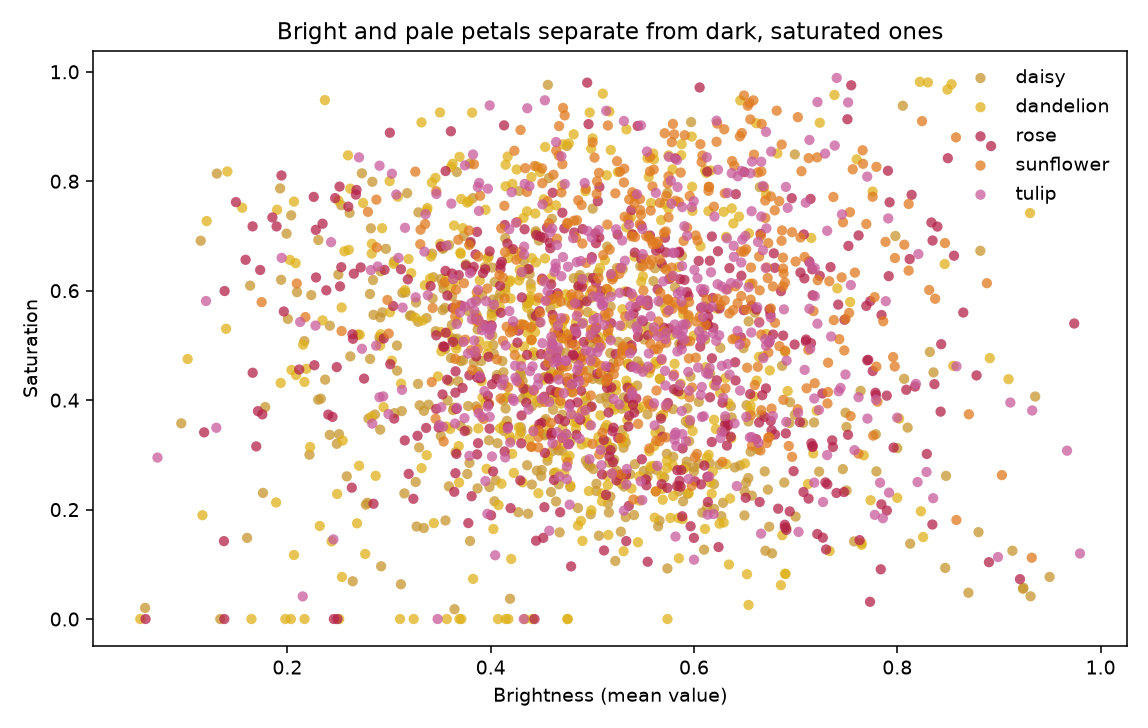

**edge_density.png**

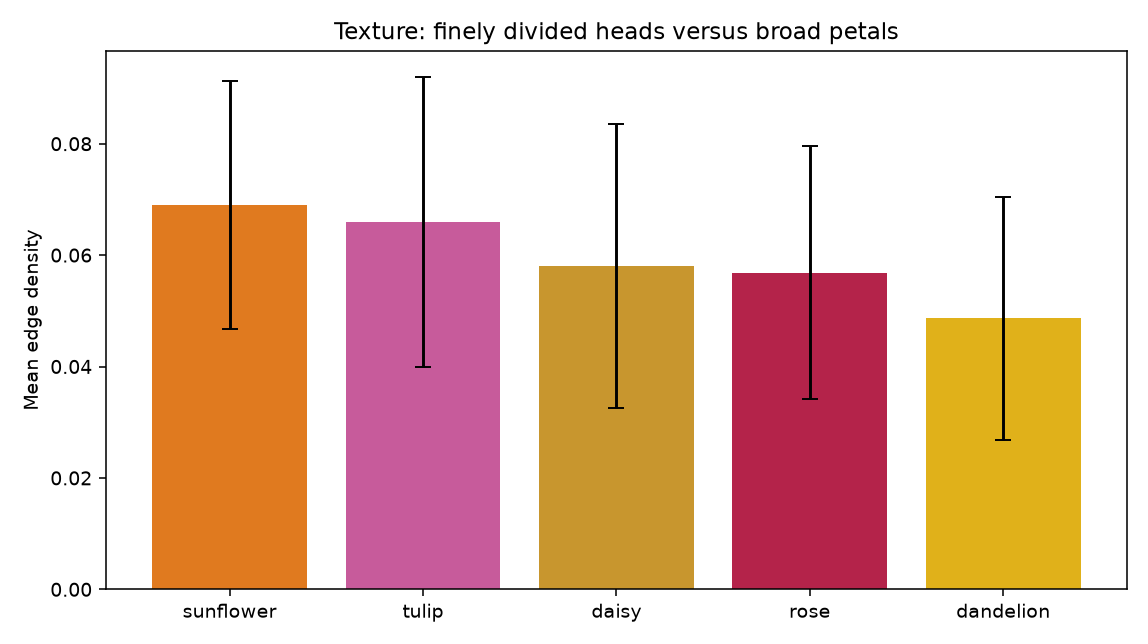

In [4]:
all_frames = pd.concat([train_frame, test_frame], ignore_index=True)
profile = (
    all_frames.groupby("label")[["brightness", "saturation", "edge_density", "yellow_ratio", "red_ratio"]]
    .mean()
    .round(3)
)
display(profile)

from PIL import Image as PilImage
for name in ("hue.png", "brightness_saturation.png", "edge_density.png"):
    path = ROOT / "ui" / "static" / "charts" / name
    if path.exists():
        display(Markdown(f"**{name}**"))
        display(PilImage.open(path))

# Charts are regenerated by training. If this is the first run, the next section writes them
# and the story. Re-open this output after training if the files were missing above.


## 5. Model training

Three classifiers see the identical scaled features:

| Model | Why it is here |
| --- | --- |
| Logistic regression | Linear baseline. If this scores well, the species are already separated by the measurements. |
| Random forest | Non-linear, handles thresholds such as "yellow ratio above 0.2", and exposes feature importance. |
| Gradient boosting | A second tree ensemble with a different bias, to see whether boosting buys accuracy on this sample. |

Selection rule: 5-fold stratified cross-validation on the **training** rows, judged by mean macro-F1. Macro-F1 treats each species equally, which matches the balanced sample. The winner is refit on all training rows. Only then is `data/test` scored. Test numbers for the other two models are printed so the comparison is visible; they were not used to pick the winner.

The saved artifact is `models/flora_vision.pkl`. It holds the fitted pipeline, the feature column order, the test metrics, and the per-species feature profiles used to explain a single prediction.


Cross-validating logistic_regression...


  CV macro-F1 0.556
Cross-validating random_forest...


  CV macro-F1 0.595
Cross-validating gradient_boosting...


  CV macro-F1 0.595
Selected gradient_boosting on training cross-validation.


Cross-validation on the training set (selection criterion: cv_f1_macro)


,model,cv_accuracy,cv_precision_macro,cv_recall_macro,cv_f1_macro,cv_f1_std,selected
2,gradient_boosting,0.598,0.595,0.598,0.595,0.021,True
1,random_forest,0.598,0.596,0.598,0.594,0.018,False
0,logistic_regression,0.560,0.560,0.560,0.556,0.015,False


... (3 outputs left out)

,precision,recall,f1,support
species,,,,
daisy,0.6222,0.700,0.6588,40.0
dandelion,0.5500,0.550,0.5500,40.0
roses,0.5946,0.550,0.5714,40.0
sunflowers,0.7073,0.725,0.7160,40.0
tulips,0.6486,0.600,0.6234,40.0


### Feature story

These readings come from 2200 flower photographs (2000 for training and 200 held out for testing) across daisy, dandelion, rose, sunflower, and tulip. Sunflower leads the three headline measurements: it is the closest to yellow, the brightest, and the most finely textured. No one of those measurements is a species label. Flowers that share a color still differ in brightness and in how broken-up the edges are, and the model uses that combination.

**Hue.** Hue is the color angle of pixels saturated enough to have a stable color, so a pale background does not drag the average toward a random angle. Sunflower is closest to yellow, at 60° (yellow). Rose is closest to red, at 31° (orange). The shorter turn between those two averages is 29°. Sunflower also has the highest share of clearly yellow pixels (22%). Species that land near each other on this wheel cannot be separated by hue alone.

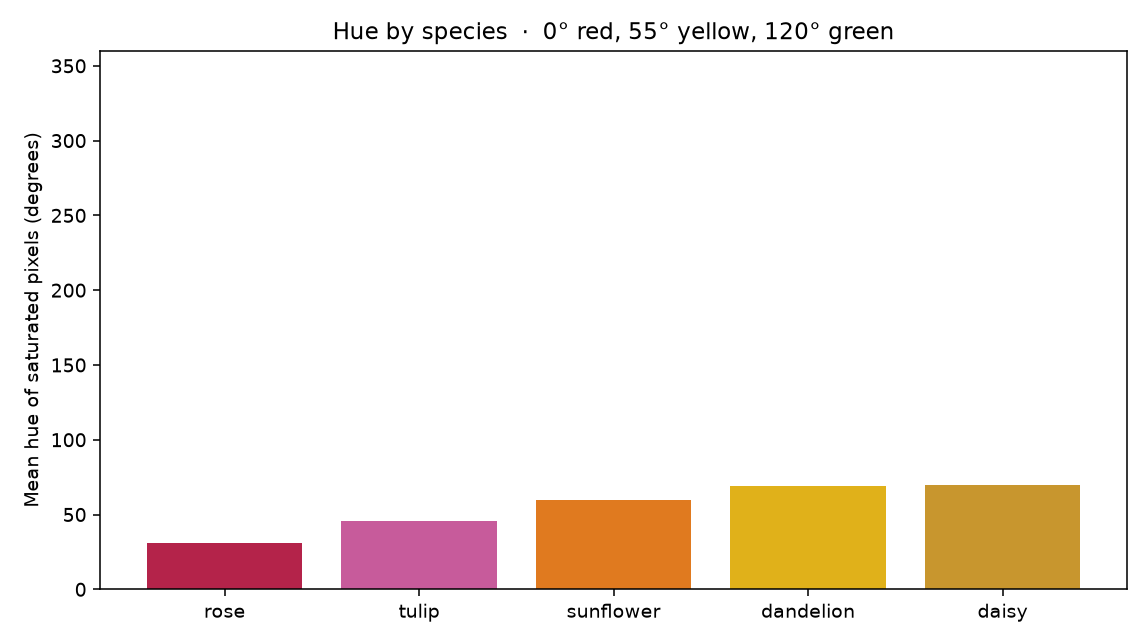

**Brightness and saturation.** Brightness is the average value channel. Saturation is how far the color sits from gray. Sunflower is the brightest species (0.56) and daisy is the darkest (0.47), a clear gap of 0.09. Sunflower is the most saturated (0.60) and daisy the least (0.43). In this sample the bright, saturated frames belong to sunflower, while daisy stays darker and closer to gray. Brightness still depends on the camera, so it supports hue rather than replacing it.

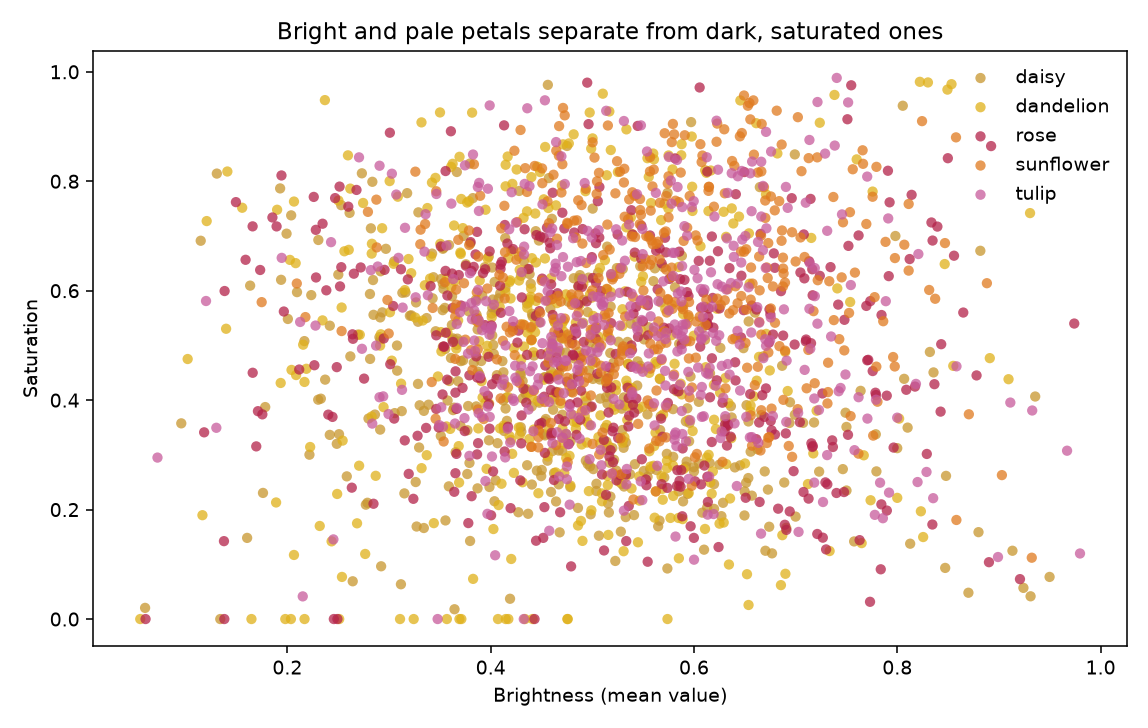

**Edge density.** Edge density is the average strength of local brightness changes after the photo is resized to 128 pixels. Sunflower has the finest texture (0.069) and dandelion the smoothest (0.049), a clear gap of 0.020. The finer species breaks the frame into smaller light-dark changes. The smoother species fills the frame with broader patches. That gap is available to the model when two species share a hue.

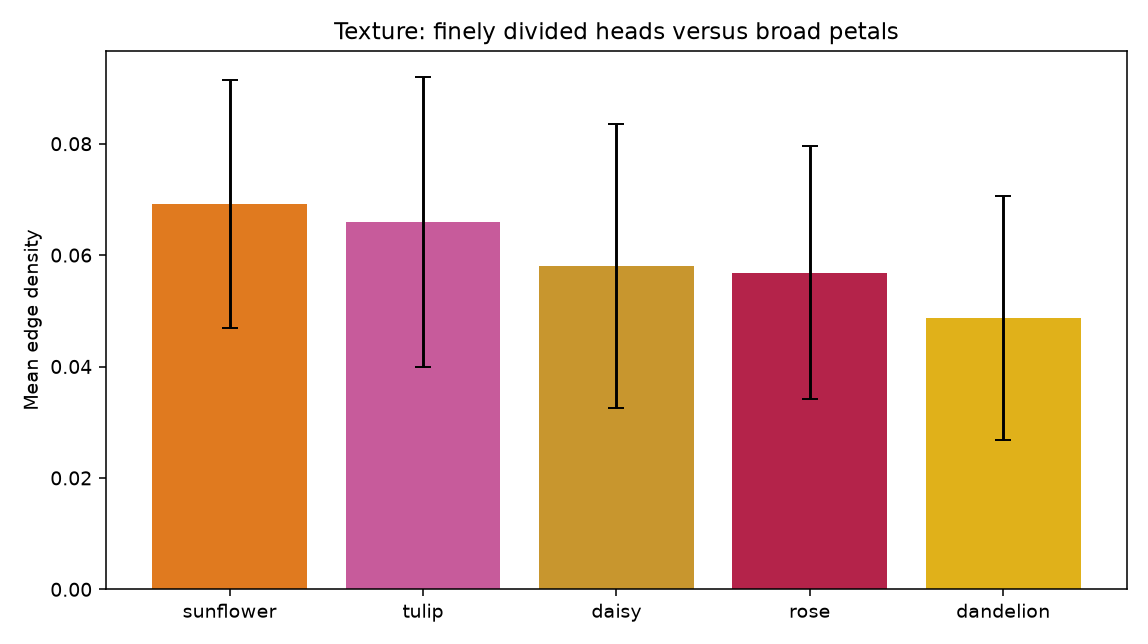

**Test confusion matrix**

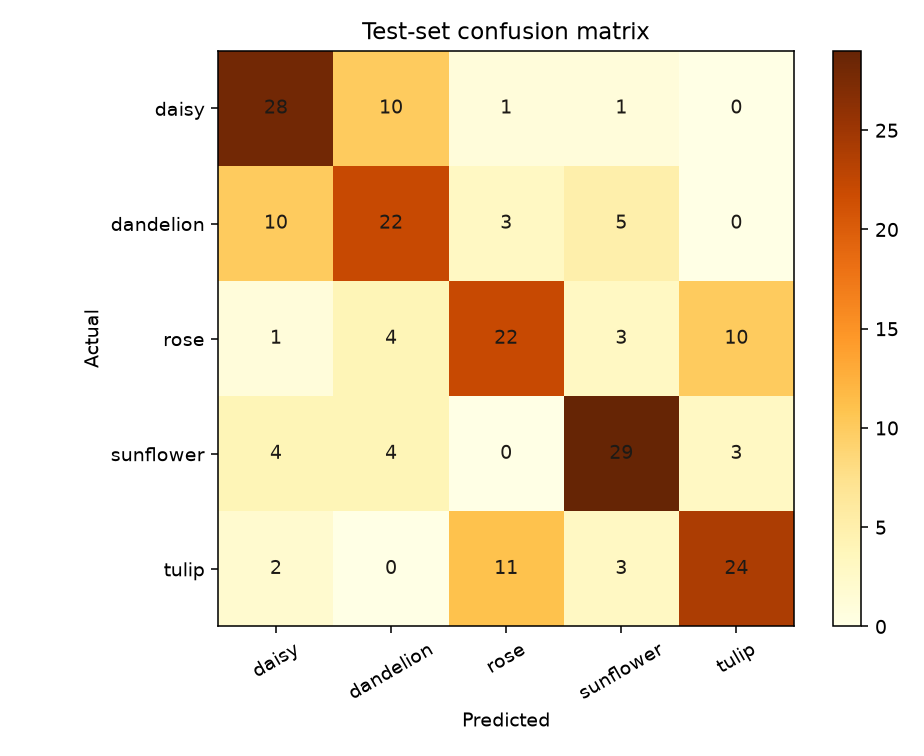

**Feature importance of the selected model**

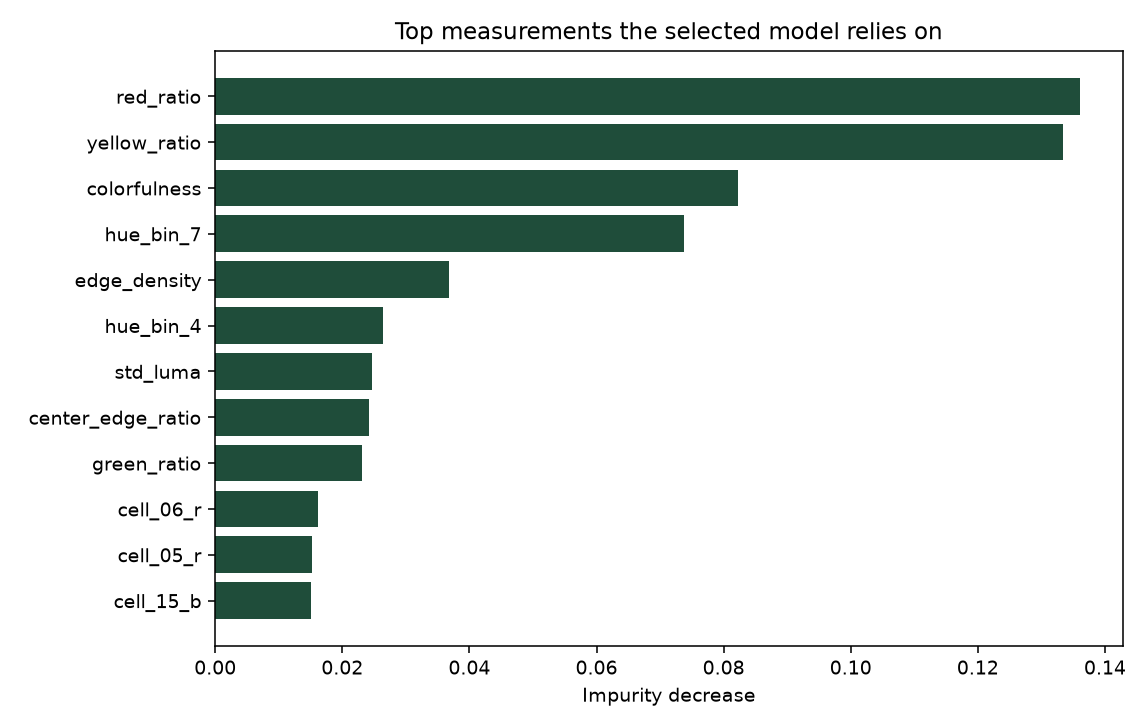

In [5]:
public = train_and_save()
cv_table = pd.DataFrame(
    [
        {
            "model": row["model"],
            "cv_accuracy": row["accuracy"]["mean"],
            "cv_precision_macro": row["precision_macro"]["mean"],
            "cv_recall_macro": row["recall_macro"]["mean"],
            "cv_f1_macro": row["f1_macro"]["mean"],
            "cv_f1_std": row["f1_macro"]["std"],
            "selected": row["model"] == public["estimator"],
        }
        for row in public["cv"]
    ]
).sort_values("cv_f1_macro", ascending=False)
print("Cross-validation on the training set (selection criterion: cv_f1_macro)")
display(cv_table.round(3))

test_table = pd.DataFrame(
    [
        {
            "model": item["model"],
            "selected": item["selected"],
            "accuracy": item["test"]["accuracy"],
            "precision_macro": item["test"]["precision_macro"],
            "recall_macro": item["test"]["recall_macro"],
            "f1_macro": item["test"]["f1_macro"],
            "f1_weighted": item["test"]["f1_weighted"],
            "roc_auc_ovr_weighted": item["test"]["roc_auc_ovr_weighted"],
        }
        for item in public["comparison"]
    ]
)
print("Held-out test set, scored after the model was chosen")
display(test_table.round(3))

selected = next(item for item in public["comparison"] if item["selected"])
per_class = pd.DataFrame(selected["test"]["per_class"]).T
per_class.index.name = "species"
print("Per-species test metrics for the deployed model")
display(per_class)

story = load_story()
display(Markdown("### Feature story"))
display(Markdown(story["overview"]))
for feature in story["features"]:
    display(Markdown(f"**{feature['title']}.** {feature['text']}"))
    display(PilImage.open(ROOT / "ui" / "static" / "charts" / feature["image"]))

display(Markdown("**Test confusion matrix**"))
display(PilImage.open(ROOT / "ui" / "static" / "charts" / "confusion.png"))
display(Markdown("**Feature importance of the selected model**"))
display(PilImage.open(ROOT / "ui" / "static" / "charts" / "importance.png"))


## 6. Prediction function

`predict_path` is what the API calls for one upload, after it has the file in memory (`predict_bytes` is the same path). It loads `models/flora_vision.pkl`, rebuilds the feature vector, and returns the species, the probability of every species, the three headline features, and a sentence that compares this photo with the training profile of the predicted species.

The loop below runs that function on two held-out photographs of each species.


In [6]:
artifact = load_artifact()
print(
    f"Loaded {artifact['estimator_name']} version {artifact['version']}, "
    f"trained at {artifact['trained_at']}"
)

rows = []
for label in CLASSES:
    for path in sorted((TEST_DIR / label).glob("*.jpg"))[:2]:
        prediction = predict_path(path)
        rows.append(
            {
                "file": path.name,
                "actual": label,
                "predicted": prediction["label"],
                "confidence": prediction["confidence"],
                "correct": prediction["label"] == label,
                "explanation": prediction["explanation"],
            }
        )
preview = pd.DataFrame(rows)
display(preview.drop(columns=["explanation"]))
print("Correct on this preview:", int(preview["correct"].sum()), "/", len(preview))
print()
print(preview.iloc[0]["explanation"])


Loaded gradient_boosting version 1, trained at 2026-11-26T09:09:10+00:00


,file,actual,predicted,confidence,correct
0,daisy_000.jpg,daisy,dandelion,0.2468,False
1,daisy_001.jpg,daisy,daisy,0.4968,True
2,dandelion_000.jpg,dandelion,dandelion,0.4168,True
3,dandelion_001.jpg,dandelion,dandelion,0.6639,True
4,roses_000.jpg,roses,roses,0.7570,True
5,roses_001.jpg,roses,sunflowers,0.3975,False
6,sunflowers_000.jpg,sunflowers,daisy,0.2981,False
7,sunflowers_001.jpg,sunflowers,sunflowers,0.5891,True
8,tulips_000.jpg,tulips,roses,0.8368,False
9,tulips_001.jpg,tulips,tulips,0.5278,True


Correct on this preview: 6 / 10

The model chose dandelion because this photo's saturated hue is 58° (yellow); brightness 0.45 is close to the dandelion average (0.48); edge density 0.037 is smoother than that average (0.049).


## 7. Retrain trigger

Retraining is not a second copy of this notebook that someone remembers to run. The API keeps uploaded photographs in `data/incoming/<species>` and calls `retrain_status`.

The trigger turns on when either of these is true:

- At least 10 new labeled photographs are waiting (`PENDING_THRESHOLD`).
- At least 5 new photographs are waiting and their average feature vector is 1.5 standard deviations away from the training distribution (`DRIFT_THRESHOLD`). Drift is the root-mean-square of the z-scores across every feature the model uses.

Pressing **Retrain model** in the UI calls `retrain`. That refits the **same** algorithm that was selected here, on the original training images plus the uploads, then scores `data/test` again. The new model replaces the old one only if test macro-F1 does not fall by more than 0.03. A worse candidate is refused and the uploads stay in the incoming folder. Force is available for a deliberate override.

This notebook does not press that button, so the evaluated test score above stays the score of the model that was just trained.


In [7]:
status = retrain_status(load_artifact())
print("Pending photographs:", status["pending"])
print("Needs retrain:", status["needs_retrain"])
print("Reasons:", status["reasons"] or "none — trigger is off until data is uploaded")
print("Drift:", status["drift"])


Pending photographs: 0
Needs retrain: False
Reasons: none — trigger is off until data is uploaded
Drift: None


## 8. Reading the result

Macro-F1 is the headline because a model can look accurate while missing one species. The confusion matrix shows which pairs still trade places; yellow species and red species are the likely overlaps, and the feature story explains why. The production evaluation button in the UI runs this same test set inside the running service, so the notebook number and the deployed number can be compared after a retrain.

Next step outside this notebook: `uvicorn api.app:app --host 127.0.0.1 --port 8000`, then open the dashboard, upload one photograph, and use the retrain panel when the trigger turns on.
